# Week 9 Active Learning Assignment: Water Pipe Survival Probability

## Task 1: Weibull CDF Curve Fitting

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from openpyxl import load_workbook
from scipy.optimize import curve_fit

Write functions to calculate Pipe Material Survival CDF and draw the graph

Load the Excel training data

In [4]:
pipe_materials_path = Path("/Users/admin/Downloads/Pipe_Material_Training_Data.xlsx")

workbook = load_workbook(pipe_materials_path, data_only=True)
sheet = workbook.active

Include the header row as the first row

In [5]:
pipe_materials_table = [
    list(row)
    for row in sheet.iter_rows(values_only=True)
]

Weibull CDF equation shown in the assignment

In [13]:
def cumulative_density_function(age, c, b, a):
    return 1 - c * np.exp(-(age / b) ** a)


def plot_cdf_curve_fit(
        table,
        material_type: str,
        line_color: str) -> tuple[float, float, float]:

    headers = table[0]
    rows = table[1:]

    material_index = headers.index("Material Type")
    life_expectancy_index = headers.index("Life Expectancy (y)")
    survival_probability_index = headers.index("Surv. Prob. (%)")
    
    # X training data: pipe age/life expectancy
    xdata = [
        row[life_expectancy_index]
        for row in rows
        if row[material_index] == material_type
    ]

    # Y training data: survival probability
    ydata = [
        row[survival_probability_index]
        for row in rows
        if row[material_index] == material_type
    ]
     # Calculate the Weibull coefficients
    coefficients, covariance = curve_fit(
        cumulative_density_function,
        xdata,
        ydata
    )

    c, b, a = coefficients

    print(
        f"Curve fitted CDF for {material_type}: "
        f"c={c}, b={b}, a={a}"
    )

    # Create ages 1–150 for the plotted curve
    age_vector = np.arange(1, 151)

    survival_probability_vector = cumulative_density_function(
        age_vector,
        c,
        b,
        a
    )

    plt.plot(
        age_vector,
        survival_probability_vector,
        color=line_color,
        label=material_type
    )

    return tuple(float(value) for value in coefficients)

Fit and plot the four pipe materials

Curve fitted CDF for Cast Iron: c=-101.18515204972083, b=90.2296517496211, a=1.7385295488806634
Curve fitted CDF for Ductile Iron: c=-103.0447491846564, b=65.39341449432031, a=1.7135618198212323
Curve fitted CDF for Galvanized Iron: c=-126.39516495449556, b=25.92641990138608, a=1.4793941371960508
Curve fitted CDF for Copper: c=-107.47743252086387, b=43.83294562977286, a=1.6910765551174165


/var/folders/h9/3yb1wdcd1rj16g25tf9k4n340000gp/T/ipykernel_60656/2248711213.py:2: RuntimeWarning: invalid value encountered in power
  return 1 - c * np.exp(-(age / b) ** a)
/var/folders/h9/3yb1wdcd1rj16g25tf9k4n340000gp/T/ipykernel_60656/2248711213.py:31: OptimizeWarning: Covariance of the parameters could not be estimated
  coefficients, covariance = curve_fit(


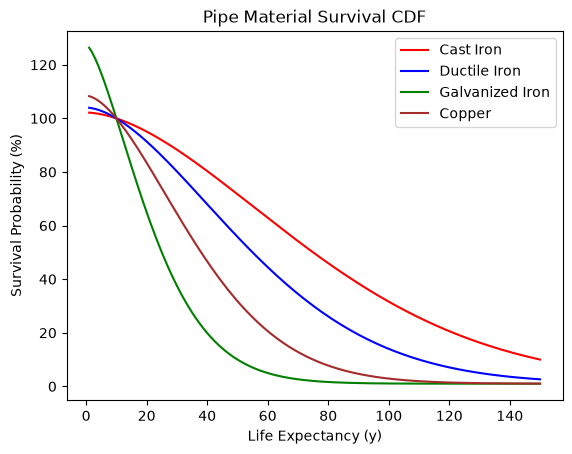

In [14]:
cast_iron_coefficients = plot_cdf_curve_fit(
    table=pipe_materials_table,
    material_type="Cast Iron",
    line_color="red"
)

ductile_iron_coefficients = plot_cdf_curve_fit(
    table=pipe_materials_table,
    material_type="Ductile Iron",
    line_color="blue"
)

galvanized_iron_coefficients = plot_cdf_curve_fit(
    table=pipe_materials_table,
    material_type="Galvanized Iron",
    line_color="green"
)

copper_coefficients = plot_cdf_curve_fit(
    table=pipe_materials_table,
    material_type="Copper",
    line_color="brown"
)

plt.legend()
plt.xlabel("Life Expectancy (y)")
plt.ylabel("Survival Probability (%)")
plt.title("Pipe Material Survival CDF")
plt.show()

## Task 2: For every water main, calculate its age, select the coefficients for its pipe material, and use the Weibull equation to estimate its survival probability

In [16]:
import csv
from datetime import datetime

In [18]:
# Read the csv
water_mains_path = Path("/Users/admin/Downloads/Water_Mains.csv")

# Match each material type with its coefficients from Task 1
coefficients_by_material = {
    "Cast Iron": cast_iron_coefficients,
    "Ductile Iron": ductile_iron_coefficients,
    "Galvanized Iron": galvanized_iron_coefficients,
    "Copper": copper_coefficients
}
# Read the Water Mains CSV
with open(
        water_mains_path,
        "r",
        newline="",
        encoding="utf-8-sig") as csv_file:

    reader = csv.reader(csv_file)
    water_mains_headers = next(reader)
    water_mains_table = list(reader)

In [19]:
# Find the required column positions
install_date_index = water_mains_headers.index("InstallDate")
material_index = water_mains_headers.index("Material")

# Add the two new column names
water_mains_headers.append("Age")
water_mains_headers.append("Survival_Probability")

current_year = datetime.now().year

Calculate age and survival probability for every pipe

In [20]:
for row in water_mains_table:

    install_date = datetime.strptime(
        row[install_date_index],
        "%m/%d/%Y %H:%M"
    )

    age = current_year - install_date.year

    material_type = row[material_index]

    coefficients = coefficients_by_material[material_type]
    c, b, a = coefficients

    survival_probability = cumulative_density_function(
        age,
        c,
        b,
        a
    )

    survival_probability = min(float(survival_probability), 100)

    row.append(age)
    row.append(survival_probability)

# Show the first five calculated rows
print(water_mains_headers)

for row in water_mains_table[:5]:
    print(row)


['MainType', 'Diameter', 'InstallDate', 'Material', 'Age', 'Survival_Probability']
['Distribution', '14', '8/9/2018 16:40', 'Galvanized Iron', 8, 100]
['Distribution', '6', '5/29/2015 15:45', 'Copper', 11, 98.58760470733822]
['Distribution', '8', '7/30/2021 16:29', 'Cast Iron', 5, 100]
['Distribution', '8', '4/11/2016 3:38', 'Copper', 10, 100.0]
['Distribution', '12', '5/12/1996 15:32', 'Cast Iron', 30, 88.31496168081627]


In [21]:
# Save the completed table to Downloads
output_csv_path = Path("/Users/admin/Downloads/Water_Mains_With_Survival.csv")

with open(
        output_csv_path,
        "w",
        newline="",
        encoding="utf-8") as output_file:

    writer = csv.writer(output_file)
    writer.writerow(water_mains_headers)
    writer.writerows(water_mains_table)

print(f"Saved completed table to {output_csv_path}")

Saved completed table to /Users/admin/Downloads/Water_Mains_With_Survival.csv


## TASK 3: draw Water Main Failure Vulnerability graph

In [23]:
# Find the Survival_Probability column
survival_probability_index = water_mains_headers.index(
    "Survival_Probability"
)

# Collect the survival probabilities
survival_probabilities = []

for row in water_mains_table:
    survival_probability = row[survival_probability_index]
    survival_probabilities.append(float(survival_probability))

# Count pipes with survival probability below 50%
low_probability_count = 0

for probability in survival_probabilities:
    if probability < 50:
        low_probability_count += 1

total_pipe_count = len(survival_probabilities)

low_probability_percent = (
    low_probability_count / total_pipe_count
) * 100

print(f"Total water mains: {total_pipe_count}")
print(
    f"Water mains below 50% survival probability: "
    f"{low_probability_count}"
)
print(
    f"Percentage below 50% survival probability: "
    f"{low_probability_percent:.2f}%"
)

Total water mains: 3250
Water mains below 50% survival probability: 71
Percentage below 50% survival probability: 2.18%


Create histogram

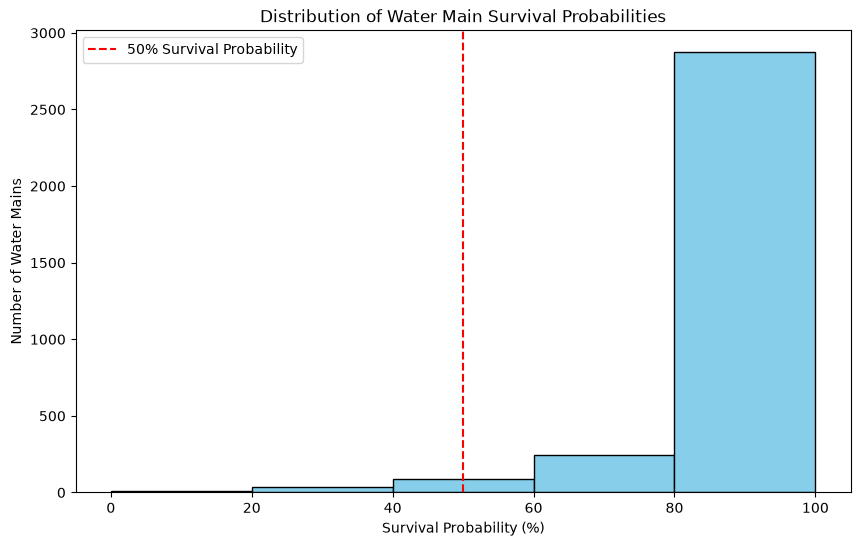

In [26]:
plt.figure(figsize=(10, 6))

plt.hist(
    survival_probabilities,
    bins=[0, 20, 40, 60, 80, 100],
    color="skyblue",
    edgecolor="black"
)

# Mark the 50% survival threshold
plt.axvline(
    x=50,
    color="red",
    linestyle="--",
    label="50% Survival Probability"
)

plt.xlabel("Survival Probability (%)")
plt.ylabel("Number of Water Mains")
plt.title("Distribution of Water Main Survival Probabilities")
plt.legend()
plt.show()